In [6]:
%pip install -U langgraph langchain langchain-core langchain-openai


  Attempting uninstall: langchain-openai

    Found existing installation: langchain-openai 1.7.4

    Uninstalling langchain-openai-1.7.4:

      Successfully uninstalled langchain-openai-1.7.4

   ---------------------------------------- 0/2 [langchain-openai]
   ---------------------------------------- 0/2 [langchain-openai]
   ---------------------------------------- 0/2 [langchain-openai]
   ---------------------------------------- 0/2 [langchain-openai]
   ---------------------------------------- 0/2 [langchain-openai]
  Attempting uninstall: langgraph
   ---------------------------------------- 0/2 [langchain-openai]
    Found existing installation: langgraph 1.2.20
   ---------------------------------------- 0/2 [langchain-openai]
   -------------------- ------------------- 1/2 [langgraph]
    Uninstalling langgraph-1.2.20:
   -------------------- ------------------- 1/2 [langgraph]
      Successfully uninstalled langgraph-1.2.20
   -------------------- ------------------- 1/2


[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
from langgraph.graph import StateGraph ,START,END
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_openai import ChatOpenAI
from langgraph.checkpoint.memory import MemorySaver

In [8]:
pip install dotenv

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
from dotenv import load_dotenv
load_dotenv()

True

In [10]:
llm = ChatOpenAI(
    model="gpt-4o-mini",
    temperature=0
)

In [11]:
from langgraph.graph.message import add_messages
class ChatState(TypedDict):
    messages : Annotated[list[BaseMessage], add_messages]

In [12]:
def chat_node(state: ChatState):
    #take user query from the messages
    messages = state['messages']
    #send to llm
    response  = llm.invoke(messages)
    # response store state
    return {'messages' : [response]}


In [13]:
checkpoint = MemorySaver() 

graph = StateGraph(ChatState)

#add nodes

graph.add_node('chat_node',chat_node)

#add edges
graph.add_edge(START,'chat_node')
graph.add_edge('chat_node',END)

chatbot = graph.compile(checkpointer=checkpoint)

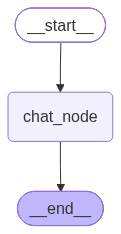

In [14]:
chatbot

In [15]:
initial_state = {
    'messages': [HumanMessage(content='What is object oriented programming?')]
}
response = chatbot.invoke(initial_state)
response['messages'][-1].content


ValueError: Checkpointer requires one or more of the following 'configurable' keys: thread_id, checkpoint_ns, checkpoint_id

In [17]:
thread_id ="1"

while True:
    user_message = input('Type here: ')
    print ('User:', user_message)

    if user_message.strip().lower() in ['exit','quit','bye']:
        break

    config = {'configurable':{'thread_id':thread_id}}    
    response = chatbot.invoke({'messages': [HumanMessage(content=user_message)]}, config=config)
    print('AI:', response['messages'][-1].content)

User: exit
